Język: [English](examples.en.ipynb) | **Polski**

# Wykład 01 — eksperyment: regresja liniowa od zera

Materiał towarzyszący [`lecture.md`](lecture.md). Implementujemy mechanizm
opisany na wykładzie: dane syntetyczne → model liniowy jako tensory
z `requires_grad=True` → strata MSE → gradient (ręczny wzór i `autograd`)
→ pętla treningowa → wizualizacja.

Prawdziwe parametry (`a_true`, `b_true`) są takie same jak w przykładzie
rozwiązanym na wykładzie (`y = 2x + 1`), żeby można było porównać wyniki.


In [1]:
import matplotlib.pyplot as plt
import torch

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")


Używane urządzenie: cpu


## 1. Dane syntetyczne

Generujemy $N$ punktów $x_i \sim \text{Uniform}(-3, 3)$ i
$y_i = a_{\text{true}} x_i + b_{\text{true}} + \varepsilon_i$, gdzie
$\varepsilon_i$ to szum gaussowski. Dane tworzymy na CPU, a następnie
przenosimy na wybrane `device` — to jest wzorzec, który będzie działał
identycznie, gdy dane będą dużo większe.


x.shape=(80,), y.shape=(80,), dtype=torch.float32, device=cpu


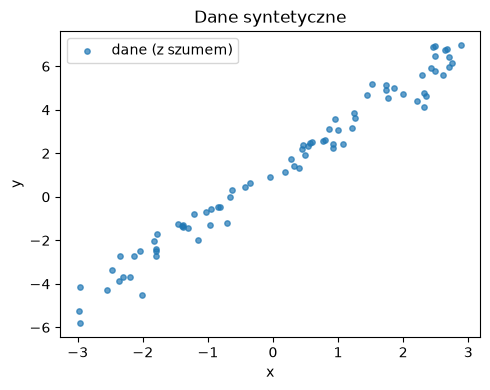

In [2]:
N = 80
a_true, b_true = 2.0, 1.0
noise_std = 0.6

x = torch.empty(N).uniform_(-3, 3)
noise = torch.randn(N) * noise_std
y = a_true * x + b_true + noise

x = x.to(device)
y = y.to(device)

print(f"x.shape={tuple(x.shape)}, y.shape={tuple(y.shape)}, dtype={x.dtype}, device={x.device}")

plt.figure(figsize=(5, 4))
plt.scatter(x.cpu(), y.cpu(), s=15, alpha=0.7, label="dane (z szumem)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dane syntetyczne")
plt.legend()
plt.tight_layout()
plt.show()


## 2. Parametry modelu

Parametry $w$ i $b$ to tensory z `requires_grad=True` — to, co odróżnia je
od zwykłych danych: PyTorch będzie śledził operacje na nich, żeby policzyć
gradient straty względem nich przy wywołaniu `.backward()`.


In [3]:
w = torch.zeros(1, requires_grad=True, device=device)
b = torch.zeros(1, requires_grad=True, device=device)
print(f"w={w.item():.4f}, b={b.item():.4f}, requires_grad(w)={w.requires_grad}")


w=0.0000, b=0.0000, requires_grad(w)=True


## 3. Jeden krok "na kartce": autograd kontra wzór ręczny

Zanim uruchomimy pełną pętlę, zweryfikujmy, że `loss.backward()` liczy
dokładnie to, co wyprowadziliśmy na wykładzie:

$$\frac{\partial L}{\partial w} = \frac{2}{N}\sum_i (\hat{y}_i - y_i) x_i,
\qquad
\frac{\partial L}{\partial b} = \frac{2}{N}\sum_i (\hat{y}_i - y_i)$$


In [4]:
y_pred = w * x + b
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

grad_w_autograd = w.grad.clone()
grad_b_autograd = b.grad.clone()

with torch.no_grad():
    error = y_pred - y
    grad_w_manual = (2.0 / N) * torch.sum(error * x)
    grad_b_manual = (2.0 / N) * torch.sum(error)

print(f"strata (w=0, b=0):      {loss.item():.4f}")
print(f"dL/dw  autograd={grad_w_autograd.item(): .4f}   wzor={grad_w_manual.item(): .4f}")
print(f"dL/db  autograd={grad_b_autograd.item(): .4f}   wzor={grad_b_manual.item(): .4f}")

assert torch.allclose(grad_w_autograd, grad_w_manual.reshape(1), atol=1e-4)
assert torch.allclose(grad_b_autograd, grad_b_manual.reshape(1), atol=1e-4)
print("OK: gradient z autograd zgadza się ze wzorem wyprowadzonym na wykladzie.")

w.grad.zero_()
b.grad.zero_()


strata (w=0, b=0):      14.3581
dL/dw  autograd=-12.7047   wzor=-12.7047
dL/db  autograd=-2.9173   wzor=-2.9173
OK: gradient z autograd zgadza się ze wzorem wyprowadzonym na wykladzie.


tensor([0.])

## 4. Pełna pętla treningowa

Zaczynamy od $w = 0$, $b = 0$ (jak w przykładzie rozwiązanym na wykładzie) i
powtarzamy: *forward → strata → backward → aktualizacja* — bez `nn.Module`
i bez `optim`, żeby mechanizm był widoczny linia po linii.


In [5]:
w = torch.zeros(1, requires_grad=True, device=device)
b = torch.zeros(1, requires_grad=True, device=device)

learning_rate = 0.05
n_epochs = 200
snapshot_epochs = {0, 5, 20, 100, n_epochs - 1}

loss_history = []
snapshots = []

for epoch in range(n_epochs):
    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())
    if epoch in snapshot_epochs:
        snapshots.append((epoch, w.item(), b.item()))

print(f"Start:  a_true={a_true}, b_true={b_true}")
print(f"Koniec: w={w.item():.4f}, b={b.item():.4f}, strata finalna={loss_history[-1]:.4f}")


Start:  a_true=2.0, b_true=1.0
Koniec: w=1.9635, b=1.0873, strata finalna=0.2990


## 5. Wizualizacja: dopasowanie i krzywa straty


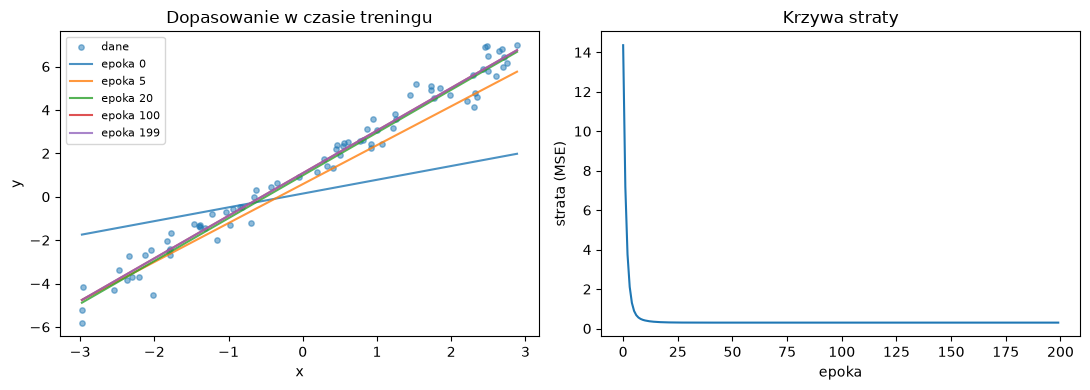

In [6]:
x_cpu = x.cpu()
y_cpu = y.cpu()
x_line = torch.linspace(x_cpu.min(), x_cpu.max(), 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(x_cpu, y_cpu, s=15, alpha=0.5, label="dane")
for epoch, w_snap, b_snap in snapshots:
    axes[0].plot(
        x_line, w_snap * x_line + b_snap,
        label=f"epoka {epoch}", alpha=0.8,
    )
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Dopasowanie w czasie treningu")
axes[0].legend(fontsize=8)

axes[1].plot(loss_history)
axes[1].set_xlabel("epoka")
axes[1].set_ylabel("strata (MSE)")
axes[1].set_title("Krzywa straty")

plt.tight_layout()
plt.show()


## 6. Co się dzieje, gdy $\eta$ jest zbyt duże?

Ten sam kod, jedyna różnica to `learning_rate`. Obserwuj krzywą straty.


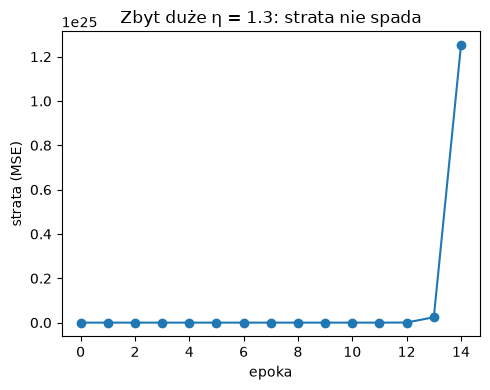

Pierwsze 5 wartości straty: ['14.36', '685.46', '35248.12', '1818082.62', '93788248.00']
Ostatnie 5 wartości straty: ['1767558812455141376.00', '91182481699277635584.00', '4703800956355763765248.00', '242653515577158096912384.00', '12517690744787223724425216.00']


In [7]:
w_big_lr = torch.zeros(1, requires_grad=True, device=device)
b_big_lr = torch.zeros(1, requires_grad=True, device=device)

learning_rate_too_big = 1.3
n_epochs_demo = 15
loss_history_big_lr = []

for epoch in range(n_epochs_demo):
    y_pred = w_big_lr * x + b_big_lr
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()
    with torch.no_grad():
        w_big_lr -= learning_rate_too_big * w_big_lr.grad
        b_big_lr -= learning_rate_too_big * b_big_lr.grad
    w_big_lr.grad.zero_()
    b_big_lr.grad.zero_()

    loss_history_big_lr.append(loss.item())

plt.figure(figsize=(5, 4))
plt.plot(loss_history_big_lr, marker="o")
plt.xlabel("epoka")
plt.ylabel("strata (MSE)")
plt.title(f"Zbyt duże η = {learning_rate_too_big}: strata nie spada")
plt.tight_layout()
plt.show()

print("Pierwsze 5 wartości straty:", [f"{v:.2f}" for v in loss_history_big_lr[:5]])
print("Ostatnie 5 wartości straty:", [f"{v:.2f}" for v in loss_history_big_lr[-5:]])


## Podsumowanie

- Gradient z `autograd` zgadza się ze wzorem wyprowadzonym ręcznie na
  wykładzie — to nie jest inna procedura, to ta sama matematyka.
- Strata zbiega do poziomu wyznaczonego przez szum w danych (nie do zera).
- Przy zbyt dużym $\eta$ ten sam kod prowadzi do rozbieżności — hiperparametr
  decyduje o tym, czy mechanizm działa, czy nie.

Pytania do dyskusji i bibliografia: zobacz [`lecture.md`](lecture.md).
